# VMR: GM from Roll Period, IMO vs Basic formula

Makes the figures and numbers in *VMR: GM from Roll Period* (Nov 2026):

- **Figure 1**: GM over time on 1 and 3 Nov with both formulas → `Figure1_GM_over_time.png`
- **Figure 2 left**: GM against roll period → `Figure2_left_GM_vs_T.png`
- **Figure 2 right**: IMO C against mean draft → `Figure2_right_C_vs_draft.png`
- **Table 1** and the bottom-line numbers

Keep the two VMR CSV files in a `data` folder next to this notebook. Needs `numpy` and `matplotlib`.

In [1]:
import csv, math, datetime as dt
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Ship (from the CSV headers): beam, mean draft, LBP, all m
B, d, L = 50.00, 18.54, 273.8
FT = 1 / 0.3048

# CargoMax GM (ft) for each day. The 3 Nov file header still holds 14.48; 14.09 is the updated figure.
DAYS = [('1 Nov 2026', 'data/20261101_061109Z.csv', 14.48),
        ('3 Nov 2026', 'data/20261103_084137Z_New-GM.csv', 14.09)]
FIG2_GM = 14.48   # CargoMax line in Figure 2 (left)

# IMO (IS Code 2008, Part A 2.3): T = 2CB/sqrt(GM),  C = 0.373 + 0.023 B/d - 0.043 L/100
C = 0.373 + 0.023 * B / d - 0.043 * L / 100
def gm_imo(T):   return (2 * C * B / T) ** 2 * FT     # ft
# Basic: T = 0.787 B / sqrt(GM)  (the IMO formula with C fixed at 0.3935)
def gm_basic(T): return (0.787 * B / T) ** 2 * FT     # ft
print(f'C = {C:.4f}, basic/IMO = (0.3935/C)^2 = {(0.3935 / C) ** 2:.3f}')

C = 0.3173, basic/IMO = (0.3935/C)^2 = 1.538


In [2]:
def load(path):
    """utc_time and roll_tp_s (roll spectrum peak, s) for every row that has a roll period."""
    t, T = [], []
    with open(path, encoding='utf-8', errors='replace') as f:
        r = csv.reader(l for l in f if not l.startswith('#'))
        h = next(r); it, ip = h.index('utc_time'), h.index('roll_tp_s')
        for row in r:
            if len(row) > ip and row[ip]:
                t.append(dt.datetime.strptime(row[it][:19], '%Y-%m-%dT%H:%M:%S')); T.append(float(row[ip]))
    return np.array(t), np.array(T)

data = [(lab, lc) + load(p) for lab, p, lc in DAYS]
for lab, lc, t, T in data: print(f'{lab}: {len(T)} roll periods, {t[0]:%H:%M}-{t[-1]:%H:%M} UTC, CargoMax {lc} ft')

1 Nov 2026: 67 roll periods, 06:13-06:54 UTC, CargoMax 14.48 ft
3 Nov 2026: 412 roll periods, 08:55-15:16 UTC, CargoMax 14.09 ft


## Table 1 and the bottom line

In [3]:
pct = lambda a: f'{a:+.0f} %'.replace('+0 ', '0 ').replace('-', '−')
rows, eI, eB, wI, wB, allT, allI, allB = [], [], [], [], [], [], [], []
for lab, lc, t, T in data:
    gi, gb = gm_imo(T), gm_basic(T)
    inI, inB = np.abs(gi - lc) <= 0.1 * lc, np.abs(gb - lc) <= 0.1 * lc
    rows.append((f'{lab[:5]} ({len(T)})', np.median(T), np.median(gi), 100 * (np.median(gi) - lc) / lc, 100 * inI.mean(),
                 np.median(gb), 100 * (np.median(gb) - lc) / lc, 100 * inB.mean()))
    eI += list(100 * (gi - lc) / lc); eB += list(100 * (gb - lc) / lc); wI += list(inI); wB += list(inB)
    allT += list(T); allI += list(gi); allB += list(gb)
# Both days: each value's error against its own day's CargoMax, then the median
rows.append((f'Both ({len(allT)})', np.median(allT), np.median(allI), np.median(eI), 100 * np.mean(wI),
             np.median(allB), np.median(eB), 100 * np.mean(wB)))
print(f'{"Day (values)":13}{"Median T":>9}{"IMO GM":>9}{"IMO err":>9}{"IMO ±10%":>10}{"Basic GM":>10}{"Basic err":>10}{"Basic ±10%":>11}')
for r in rows:
    print(f'{r[0]:13}{r[1]:8.1f}s{r[2]:7.1f}ft{pct(r[3]):>9}{r[4]:9.0f}%{r[5]:8.1f}ft{pct(r[6]):>10}{r[7]:10.0f}%')
day = rows[:-1]
print(f'\nBottom line: IMO within {max(abs(r[3]) for r in day):.0f} % of CargoMax on both days (median), '
      f'{rows[-1][4]:.0f} % of {len(allT)} values inside ±10 %. Basic {min(r[6] for r in day):.0f}–{max(r[6] for r in day):.0f} % high.')

Day (values)  Median T   IMO GM  IMO err  IMO ±10%  Basic GM Basic err Basic ±10%
1 Nov (67)       14.9s   14.9ft     +3 %       72%    22.9ft     +58 %         0%
3 Nov (412)      15.4s   13.9ft     −1 %       99%    21.4ft     +52 %         0%
Both (479)       15.3s   14.1ft      0 %       95%    21.7ft     +54 %         0%

Bottom line: IMO within 3 % of CargoMax on both days (median), 95 % of 479 values inside ±10 %. Basic 52–58 % high.


## Figures

In [4]:
INK, MUT, GRID = '#1f2933', '#5a6570', '#e3e8ec'
C_IMO, C_BAS, C_LC = '#2a7f8e', '#c2410c', '#1f3a5f'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8, 'axes.edgecolor': '#c9d3d8', 'axes.labelcolor': INK,
                     'xtick.color': MUT, 'ytick.color': MUT, 'axes.titlecolor': INK, 'axes.titlesize': 8.5,
                     'axes.titleweight': 'bold', 'legend.fontsize': 7.2})
def style(ax):
    ax.grid(True, color=GRID, lw=0.7); ax.set_axisbelow(True)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)

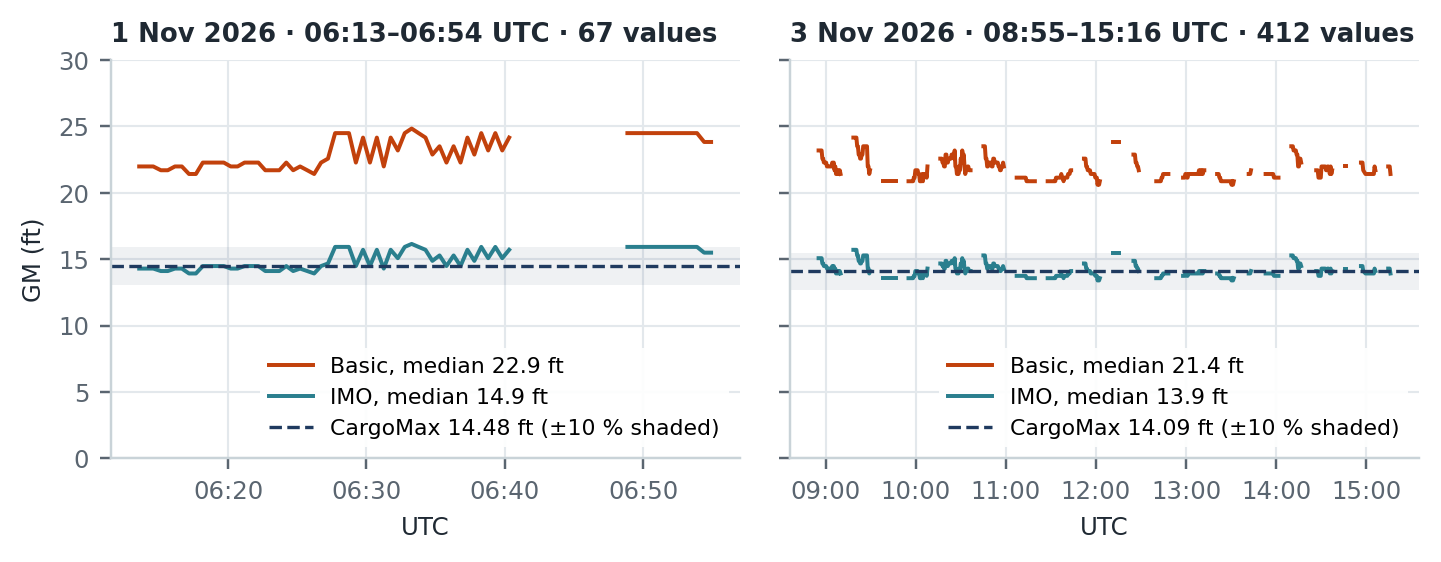

In [5]:
# Figure 1: GM over time. Gaps over 2 min between roll periods are left as gaps.
fig, axs = plt.subplots(1, 2, figsize=(6.5, 2.55), dpi=220, sharey=True,
                        gridspec_kw=dict(wspace=0.08, left=0.075, right=0.99, top=0.88, bottom=0.17))
for ax, (lab, lc, t, T) in zip(axs, data):
    gi, gb = gm_imo(T), gm_basic(T)
    seg = [0] + [j for j in range(1, len(t)) if (t[j] - t[j - 1]).total_seconds() > 120] + [len(t)]
    for y, c, n in ((gb, C_BAS, f'Basic, median {np.median(gb):.1f} ft'), (gi, C_IMO, f'IMO, median {np.median(gi):.1f} ft')):
        for a, b in zip(seg[:-1], seg[1:]): ax.plot(t[a:b], y[a:b], color=c, lw=1.3, label=n if a == 0 else None)
    ax.axhspan(lc * 0.9, lc * 1.1, color=C_LC, alpha=0.07, lw=0)
    ax.axhline(lc, color=C_LC, lw=1.1, ls='--', label=f'CargoMax {lc} ft (±10 % shaded)')
    ax.set_title(f'{lab} · {t[0]:%H:%M}–{t[-1]:%H:%M} UTC · {len(T)} values', loc='left')
    ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=range(0, 60, 10)) if (t[-1] - t[0]).total_seconds() < 7200 else mdates.HourLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M')); ax.set_xlabel('UTC'); style(ax)
    ax.legend(loc='lower right', frameon=True, framealpha=0.92, edgecolor='none')
axs[0].set_ylabel('GM (ft)'); axs[0].set_ylim(0, 30)
fig.savefig('Figure1_GM_over_time.png', facecolor='white'); plt.show()

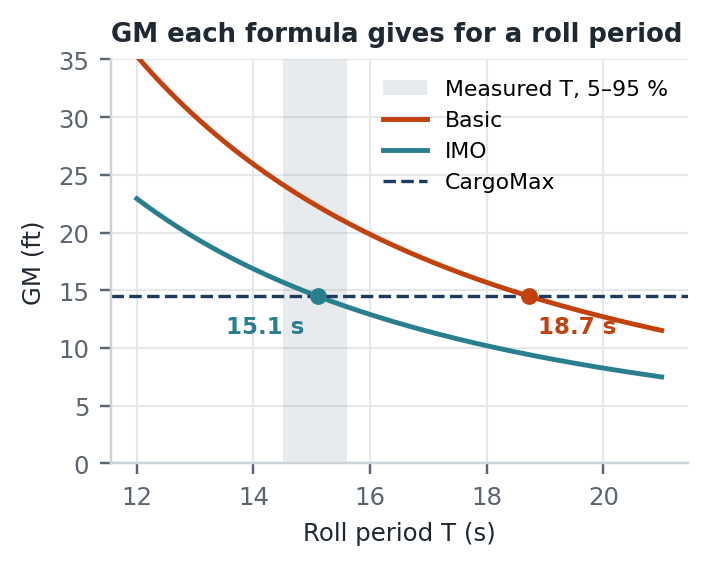

In [6]:
# Figure 2 left: the GM each formula gives for a roll period, with where each meets CargoMax
fig, ax = plt.subplots(figsize=(3.2, 2.55), dpi=220); fig.subplots_adjust(left=0.15, right=0.97, top=0.89, bottom=0.17)
Ts, aT = np.linspace(12, 21, 200), np.array(allT)
ax.axvspan(np.percentile(aT, 5), np.percentile(aT, 95), color='#9aa5ae', alpha=0.22, lw=0, label='Measured T, 5–95 %')
ax.plot(Ts, gm_basic(Ts), color=C_BAS, lw=1.6, label='Basic'); ax.plot(Ts, gm_imo(Ts), color=C_IMO, lw=1.6, label='IMO')
ax.axhline(FIG2_GM, color=C_LC, lw=1.1, ls='--', label='CargoMax')
gm_m = FIG2_GM * 0.3048
for Tm, c in ((2 * C * B / math.sqrt(gm_m), C_IMO), (0.787 * B / math.sqrt(gm_m), C_BAS)):
    ax.plot([Tm], [FIG2_GM], 'o', color=c, ms=4.5, zorder=5)
    ax.annotate(f'{Tm:.1f} s', (Tm, FIG2_GM), xytext=((-30 if c == C_IMO else 3), -12), textcoords='offset points', color=c, fontsize=7.5, fontweight='bold')
ax.set_xlabel('Roll period T (s)'); ax.set_ylabel('GM (ft)'); ax.set_ylim(0, 35); style(ax)
ax.set_title('GM each formula gives for a roll period', loc='left'); ax.legend(frameon=False, loc='upper right')
fig.savefig('Figure2_left_GM_vs_T.png', facecolor='white'); plt.show()

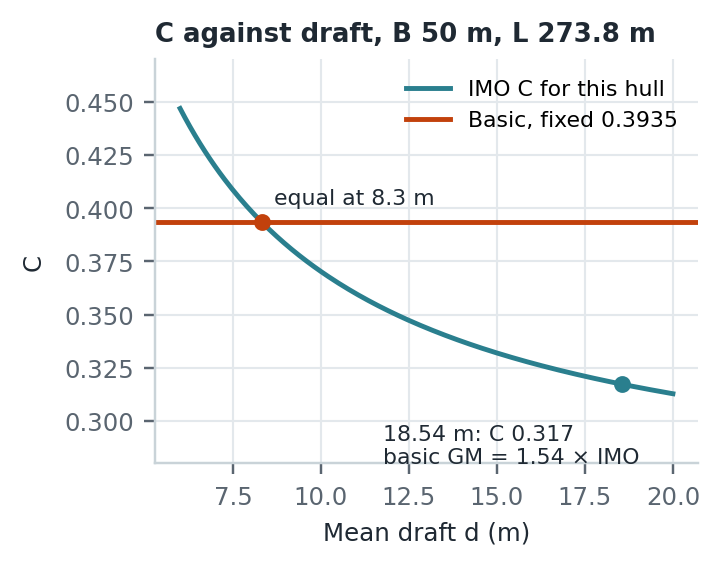

In [7]:
# Figure 2 right: IMO C for this hull against mean draft, and the basic formula's fixed C
fig, ax = plt.subplots(figsize=(3.2, 2.55), dpi=220); fig.subplots_adjust(left=0.2, right=0.97, top=0.89, bottom=0.17)
ds = np.linspace(6, 20, 200); Cd = 0.373 + 0.023 * B / ds - 0.043 * L / 100
dx = 0.023 * B / (0.3935 - 0.373 + 0.043 * L / 100)      # draft where the IMO C = 0.3935
ax.plot(ds, Cd, color=C_IMO, lw=1.6, label='IMO C for this hull'); ax.axhline(0.3935, color=C_BAS, lw=1.6, label='Basic, fixed 0.3935')
ax.plot([d], [C], 'o', color=C_IMO, ms=4.5, zorder=5)
ax.annotate(f'{d:.2f} m: C {C:.3f}\nbasic GM = {(0.3935 / C) ** 2:.2f} × IMO', (d, C), xytext=(-78, -26), textcoords='offset points', fontsize=7.2, color=INK)
ax.plot([dx], [0.3935], 'o', color=C_BAS, ms=4.5, zorder=5)
ax.annotate(f'equal at {dx:.1f} m', (dx, 0.3935), xytext=(4, 6), textcoords='offset points', fontsize=7.2, color=INK)
ax.set_xlabel('Mean draft d (m)'); ax.set_ylabel('C', labelpad=6); ax.set_ylim(0.28, 0.47); style(ax)
ax.set_title('C against draft, B 50 m, L 273.8 m', loc='left'); ax.legend(frameon=False, loc='upper right')
fig.savefig('Figure2_right_C_vs_draft.png', facecolor='white'); plt.show()